In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SOURCE_DATA_DIR = Path(os.environ["SOURCE_DATA_DIR"])
OUTPUT_DATA_DIR = Path(os.environ["OUTPUT_DATA_DIR"])


In [2]:
import sys
sys.path.insert(0, str(Path("__file__").resolve().parent.parent))
from analysis.clustering import load_traces, load_scene_patterns


In [3]:
# Validated categorical palette (dataviz skill), fixed hue order — never cycled.
# Paired with a distinct marker per slot as secondary encoding, since a trajectory
# scatter/line plot needs all-pairs separation, not just adjacent-pair separation.
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                  "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
CLUSTER_MARKERS = ["o", "s", "^", "D", "P", "X", "*", "v"]
NOISE_COLOR = "#898781"   # muted ink — HDBSCAN noise (-1)
OTHER_COLOR = "#c3c2b7"   # muted ink — clusters beyond the 8 direct-labeled slots
N_DIRECT_CLUSTERS = 8      # clusters beyond this rank (by size) fold into "other"


Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_summary.png


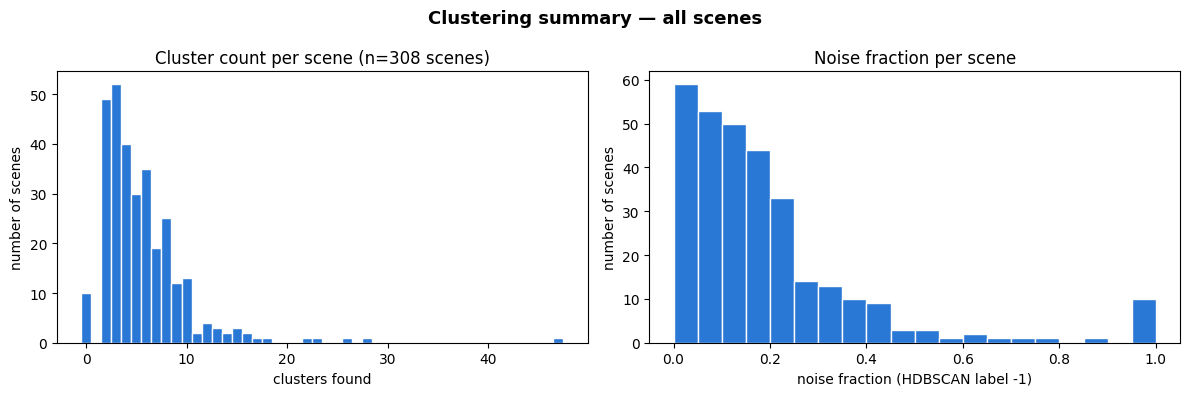

In [4]:
# --- Summary across all clustered scenes: cluster count & noise fraction ---
cluster_files = sorted((OUTPUT_DATA_DIR / "clusters").glob("*_clusters.json"))

scene_ids, n_clusters_list, noise_frac_list = [], [], []
for f in cluster_files:
    result = json.loads(f.read_text())
    labels = result["labels"]
    n_found = len(set(l for l in labels if l != -1))
    noise_frac = labels.count(-1) / len(labels) if labels else 0.0
    scene_ids.append(result["scene"])
    n_clusters_list.append(n_found)
    noise_frac_list.append(noise_frac)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(n_clusters_list, bins=range(0, max(n_clusters_list) + 2),
             color=CLUSTER_COLORS[0], edgecolor="#fcfcfb", align="left")
axes[0].set_xlabel("clusters found")
axes[0].set_ylabel("number of scenes")
axes[0].set_title(f"Cluster count per scene (n={len(scene_ids)} scenes)")

axes[1].hist(noise_frac_list, bins=20, color=CLUSTER_COLORS[0], edgecolor="#fcfcfb")
axes[1].set_xlabel("noise fraction (HDBSCAN label -1)")
axes[1].set_ylabel("number of scenes")
axes[1].set_title("Noise fraction per scene")

fig.suptitle("Clustering summary — all scenes", fontsize=13, fontweight="bold")
fig.tight_layout()

out_path = OUTPUT_DATA_DIR / "clusters" / "figure_clustering_summary.png"
fig.savefig(out_path, dpi=150, bbox_inches="tight")
print(f"Saved -> {out_path}")
plt.show()


In [5]:
# --- Detail plots: trajectories colored by cluster, for a handful of example scenes ---
# Edit this list to inspect other scenes (must have a matching <scene_id>_clusters.json).
SCENES_TO_PLOT = [scene_ids[i] for i in np.linspace(0, len(scene_ids) - 1, 4).astype(int)]
print("Plotting detail for:", SCENES_TO_PLOT)


Plotting detail for: ['w1l1s0', 'w3l3s5', 'w6l2s16', 'w8l3s9']


Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w1l1s0.png


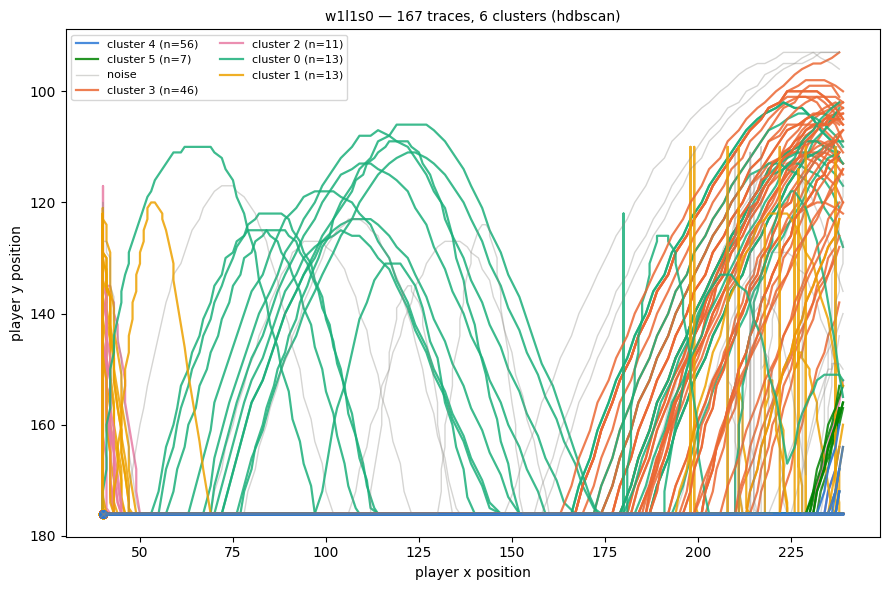

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w3l3s5.png


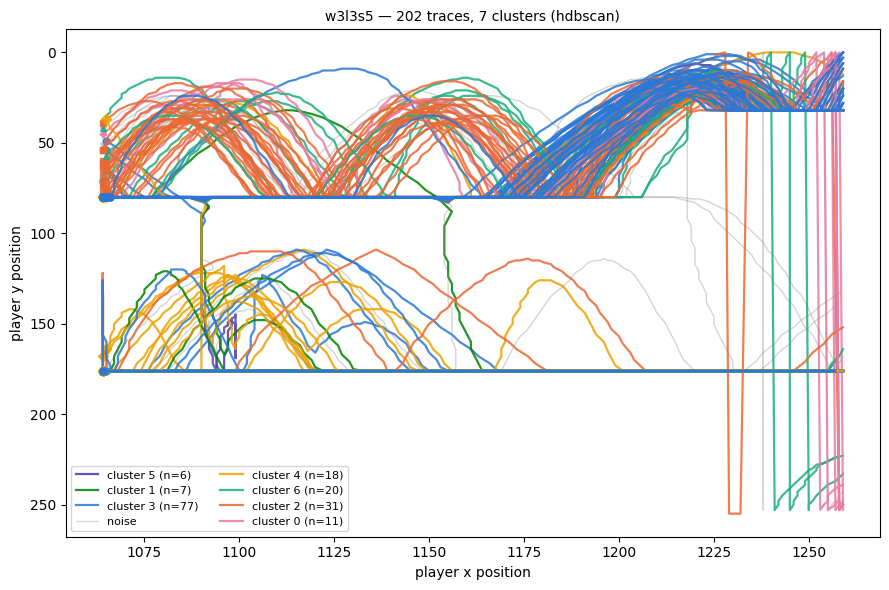

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w6l2s16.png


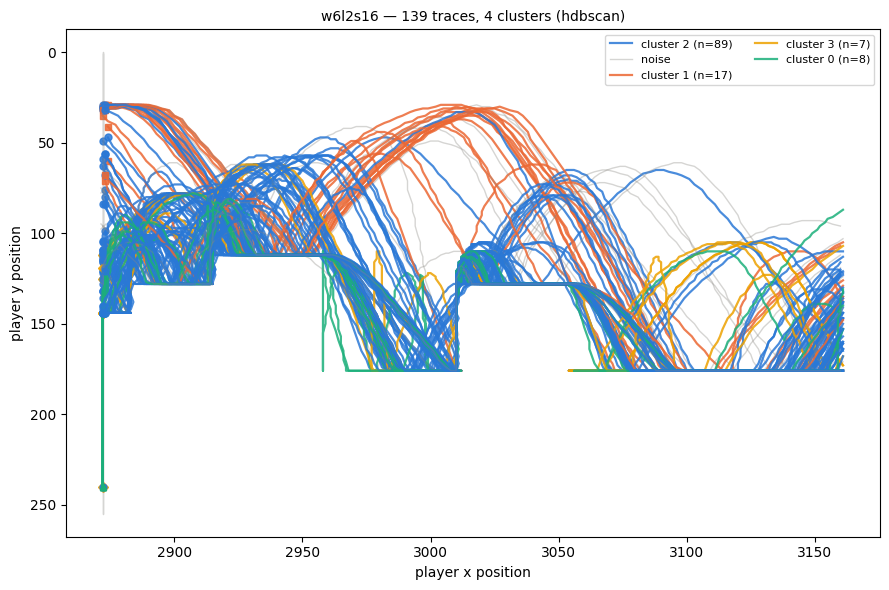

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w8l3s9.png


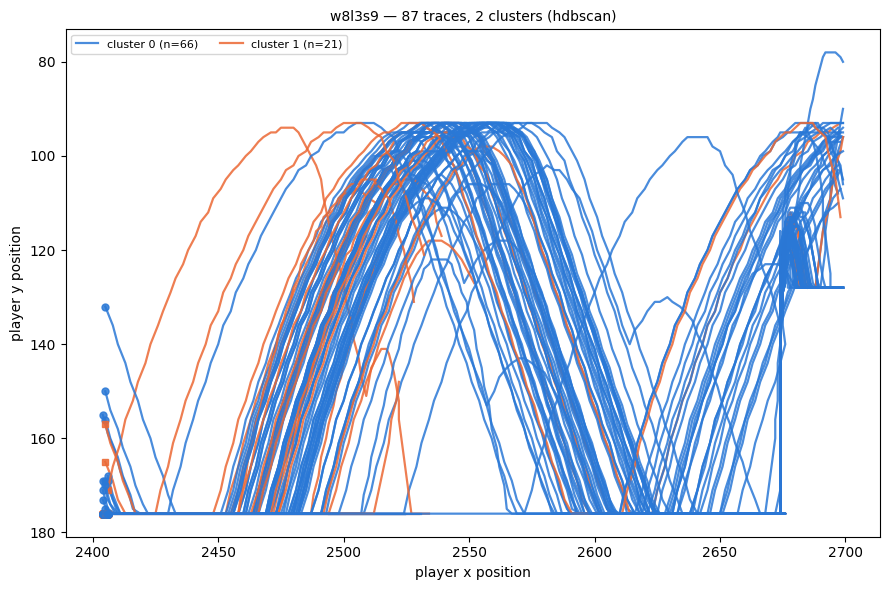

In [6]:
def plot_scene_clusters(scene_id, ax=None, title_fontsize=None, legend_fontsize=8):
    """Draw one scene's trajectories colored by cluster onto `ax` (own figure if None)."""
    cluster_path = OUTPUT_DATA_DIR / "clusters" / f"{scene_id}_clusters.json"
    result = json.loads(cluster_path.read_text())
    labels = np.array(result["labels"])
    method = result["method"]

    traces, metadata = load_traces(scene_id, SOURCE_DATA_DIR)
    if not traces:
        print(f"No trace data found for scene {scene_id}, skipping plot.")
        return None

    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(9, 6))

    # rank clusters by size so the most common behaviours get direct colors
    sizes = {l: int((labels == l).sum()) for l in set(labels.tolist()) if l != -1}
    ranked = sorted(sizes, key=sizes.get, reverse=True)
    direct = {l: i for i, l in enumerate(ranked[:N_DIRECT_CLUSTERS])}

    seen_legend = set()
    for trace, label in zip(traces, labels):
        if label == -1:
            color, marker, name = NOISE_COLOR, "x", "noise"
        elif label in direct:
            slot = direct[label]
            color, marker, name = CLUSTER_COLORS[slot], CLUSTER_MARKERS[slot], f"cluster {label} (n={sizes[label]})"
        else:
            color, marker, name = OTHER_COLOR, ".", "other clusters"

        alpha = 0.35 if label == -1 or label not in direct else 0.85
        lw = 1.0 if label == -1 or label not in direct else 1.6
        label_kw = {"label": name} if name not in seen_legend else {}
        seen_legend.add(name)

        ax.plot(trace[:, 0], trace[:, 1], color=color, alpha=alpha, linewidth=lw, **label_kw)
        ax.plot(trace[0, 0], trace[0, 1], color=color, marker=marker, markersize=5, alpha=alpha)

    ax.set_xlabel("player x position")
    ax.set_ylabel("player y position")
    ax.invert_yaxis()  # NES screen coords: y=0 is the top of the screen
    ax.set_title(f"{scene_id} — {len(traces)} traces, {len(ranked)} clusters ({method})",
                 fontsize=title_fontsize)
    ax.legend(loc="best", fontsize=legend_fontsize, ncol=2)

    if standalone:
        fig.tight_layout()
        out_path = OUTPUT_DATA_DIR / "clusters" / f"figure_clustering_{scene_id}.png"
        fig.savefig(out_path, dpi=150, bbox_inches="tight")
        print(f"Saved -> {out_path}")
        plt.show()
    return ax


for scene_id in SCENES_TO_PLOT:
    plot_scene_clusters(scene_id)


In [7]:
# --- Cluster stats by scene category (pattern tag) ---
# scenes_mastersheet.csv tags each scene with one or more design-pattern labels
# (e.g. "2-Horde", "Gap stair valley"); a scene can carry several tags at once,
# so it contributes to each of its categories below (see analysis/clustering.py
# load_scene_patterns and source_data/CONTENT.md).
patterns_long = load_scene_patterns(SOURCE_DATA_DIR)

scene_stats = pd.DataFrame({
    "scene_id": scene_ids,
    "n_clusters": n_clusters_list,
    "noise_frac": noise_frac_list,
})
category_stats = patterns_long.merge(scene_stats, on="scene_id", how="inner")
print(f"{category_stats['pattern'].nunique()} categories, "
      f"{category_stats['scene_id'].nunique()} scenes with a cluster result and a category tag")


27 categories, 305 scenes with a cluster result and a category tag


Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_by_category.png


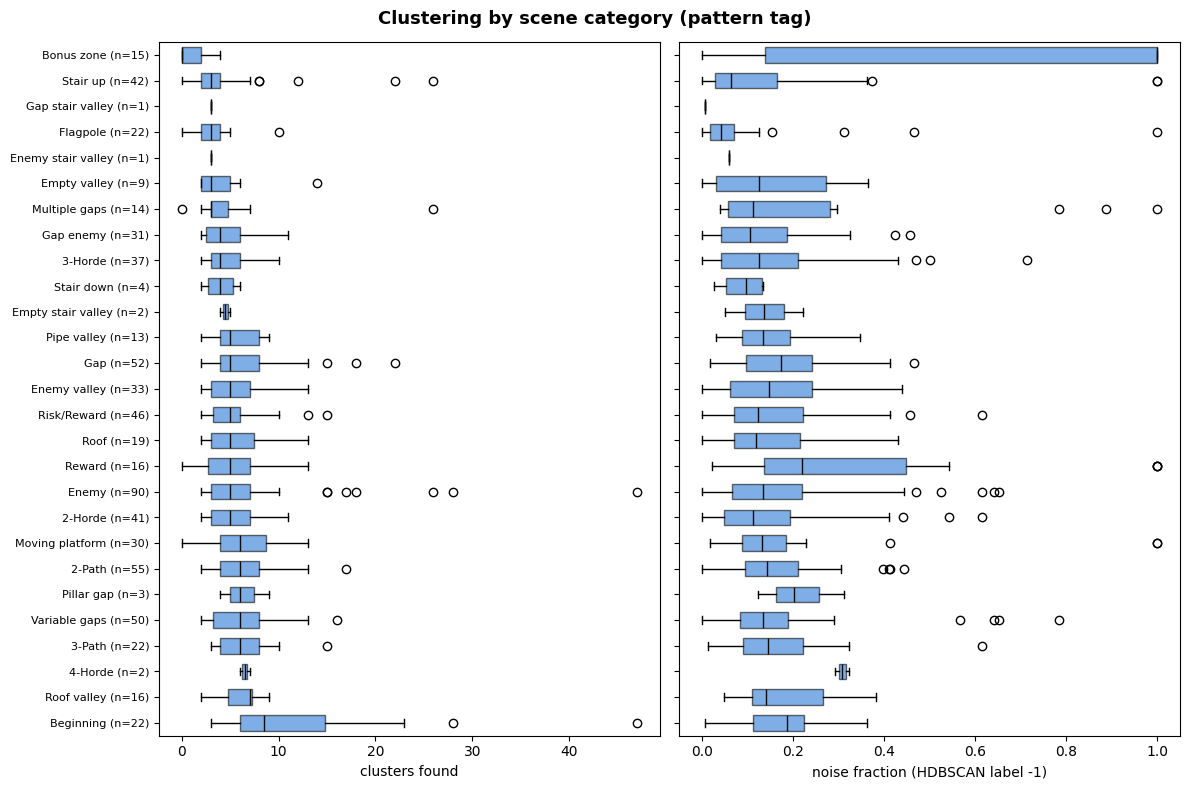

In [8]:
order = (category_stats.groupby("pattern")["n_clusters"].median()
         .sort_values(ascending=False).index)

fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)

for ax, col, xlabel in zip(
    axes,
    ["n_clusters", "noise_frac"],
    ["clusters found", "noise fraction (HDBSCAN label -1)"],
):
    data = [category_stats.loc[category_stats["pattern"] == cat, col] for cat in order]
    bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.6,
                     medianprops={"color": "#0b0b0b"})
    for box in bp["boxes"]:
        box.set(facecolor=CLUSTER_COLORS[0], alpha=0.6, edgecolor="#0b0b0b")
    ax.set_xlabel(xlabel)

axes[0].set_yticks(range(1, len(order) + 1))
n_scenes_per_cat = category_stats.groupby("pattern")["scene_id"].nunique()
axes[0].set_yticklabels([f"{cat} (n={n_scenes_per_cat[cat]})" for cat in order], fontsize=8)

fig.suptitle("Clustering by scene category (pattern tag)", fontsize=13, fontweight="bold")
fig.tight_layout()

out_path = OUTPUT_DATA_DIR / "clusters" / "figure_clustering_by_category.png"
fig.savefig(out_path, dpi=150, bbox_inches="tight")
print(f"Saved -> {out_path}")
plt.show()


Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_category_gap_stair_valley.png


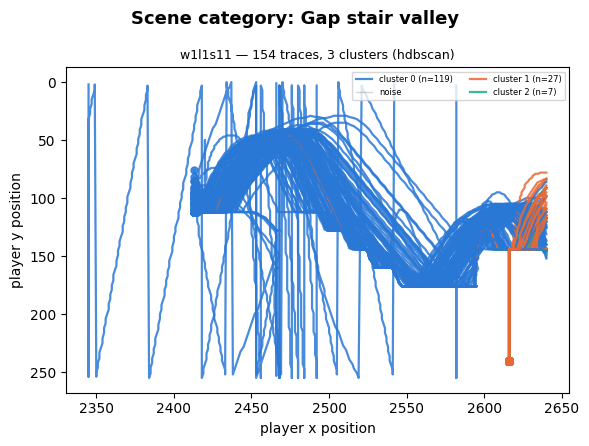

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_category_2-horde.png


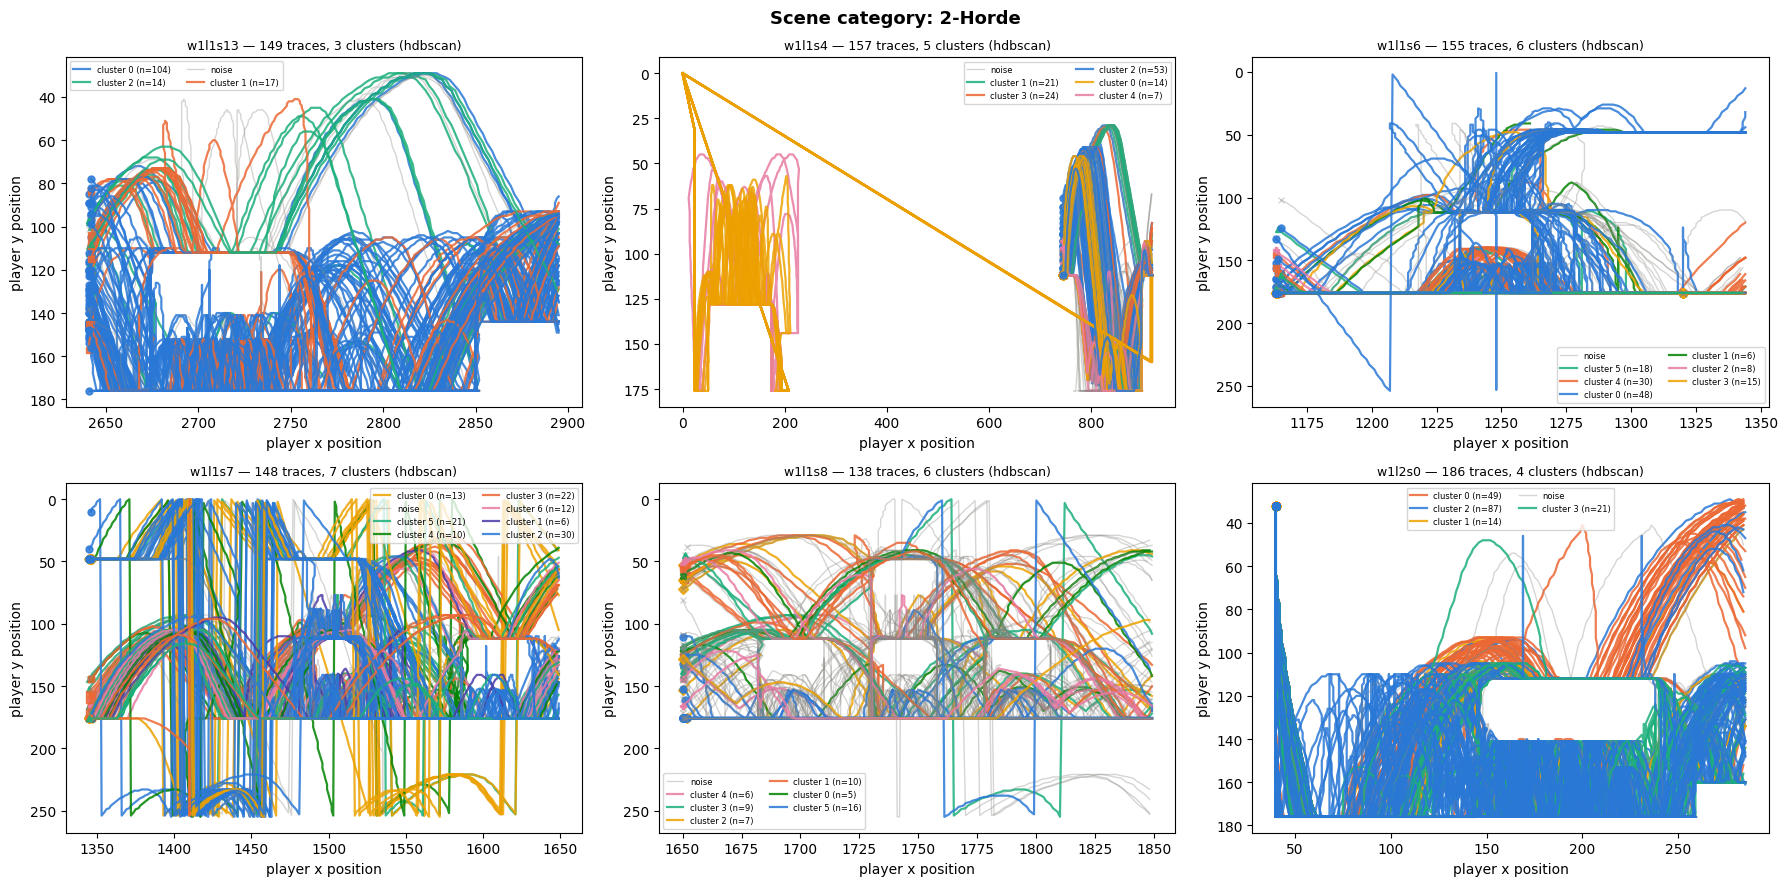

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_category_flagpole.png


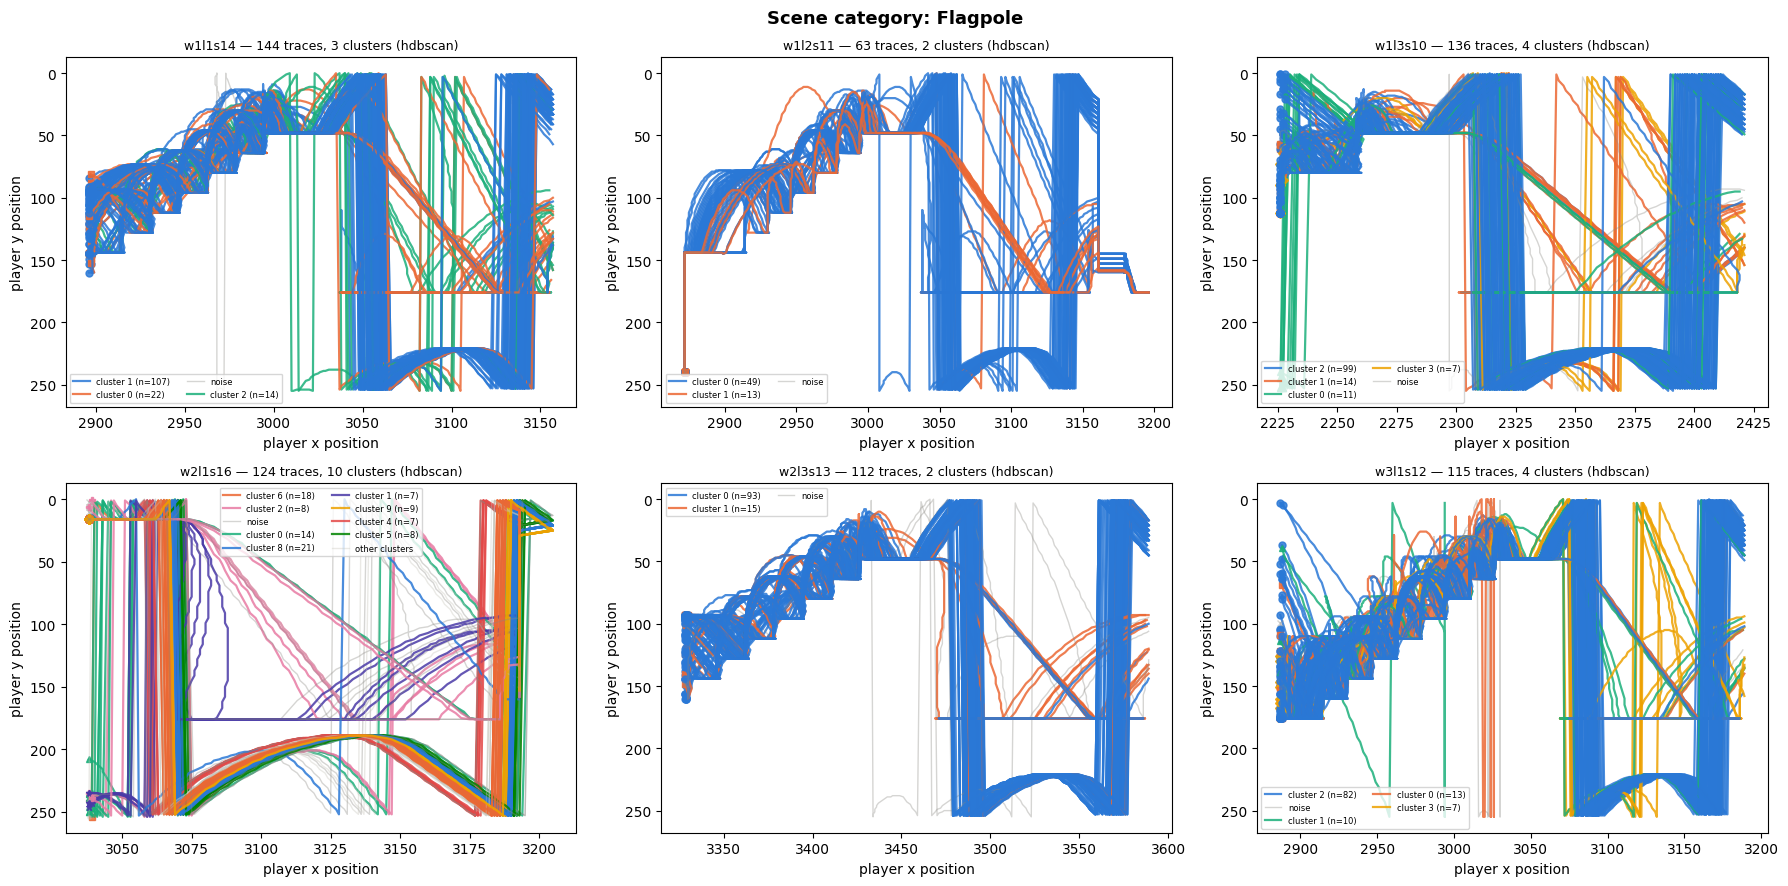

In [9]:
# --- Detail plots: one small-multiples figure per category, one subplot per scene ---
# Edit this list to inspect other categories (must be a column in scenes_mastersheet.csv).
CATEGORIES_TO_PLOT = ["Gap stair valley", "2-Horde", "Flagpole"]
MAX_SCENES_PER_CATEGORY = 6  # cap so the grid stays legible; edit freely


def plot_category_grid(category):
    scenes_in_cat = sorted(patterns_long.loc[patterns_long["pattern"] == category, "scene_id"].unique())
    if not scenes_in_cat:
        print(f"No scenes tagged '{category}', skipping.")
        return
    scenes_in_cat = scenes_in_cat[:MAX_SCENES_PER_CATEGORY]

    cols = min(3, len(scenes_in_cat))
    rows = (len(scenes_in_cat) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4.5 * rows), squeeze=False)

    for i, scene_id in enumerate(scenes_in_cat):
        ax = axes[i // cols][i % cols]
        plot_scene_clusters(scene_id, ax=ax, title_fontsize=9, legend_fontsize=6)
    for i in range(len(scenes_in_cat), rows * cols):
        axes[i // cols][i % cols].axis("off")

    fig.suptitle(f"Scene category: {category}", fontsize=13, fontweight="bold")
    fig.tight_layout()

    slug = category.lower().replace(" ", "_").replace("/", "-")
    out_path = OUTPUT_DATA_DIR / "clusters" / f"figure_clustering_category_{slug}.png"
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    print(f"Saved -> {out_path}")
    plt.show()


for category in CATEGORIES_TO_PLOT:
    plot_category_grid(category)
